# Threat modelling and risk scoring, end to end

**Module 04 — AI Threat Modeling and Risk Assessment**

A threat model is not a list of scary things. It is an argument that connects an asset, a path an
attacker could take, a control that interrupts that path, and a number that lets two people compare
priorities. This notebook builds that argument for a triage assistant and then attacks its own
conclusions.

## Learning objectives

1. Produce a data-flow inventory with trust boundaries for a small AI system.
2. Map threats onto STRIDE categories and to MITRE ATLAS where the threat is ML-specific.
3. Build an attack tree and identify the cheapest path to a goal.
4. Score risks transparently and rank them.
5. Find the threat your model omits, which is the one that matters.

## Background

Two ideas from Module 04 do the work here. First, **a threat is only meaningful relative to an asset**
— "prompt injection" is not a risk; "prompt injection that makes the assistant recommend discharge" is.
Second, **severity is a product of impact and likelihood, and both must be argued**, not asserted.

STRIDE gives a checklist (Spoofing, Tampering, Repudiation, Information disclosure, Denial of service,
Elevation of privilege). MITRE ATLAS gives ML-specific techniques. Neither is exhaustive; both are ways
of not staring at a blank page.

## Dependencies and installation

```bash
python -m pip install "pandas>=2.2" "matplotlib>=3.9"
```

No model training and no network access. Runtime is a couple of seconds on CPU.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)

SYSTEM = "clinical triage assistant (summarises referrals, suggests urgency)"
print("Target system:", SYSTEM)

Target system: clinical triage assistant (summarises referrals, suggests urgency)


**Expected output** — one line naming the system under assessment. Write the name down before writing
threats: a model of "AI in healthcare" cannot be validated, a model of *this* assistant can.

### Step 1 — Assets, flows and boundaries

Each row is an asset with an owner and a sensitivity. Each flow is a movement of data, marked with
whether it crosses a trust boundary.

In [2]:
assets = pd.DataFrame(
    [
        ("A1", "referral documents", "untrusted content", "high"),
        ("A2", "triage model", "internal artefact", "high"),
        ("A3", "patient identifiers", "personal data", "critical"),
        ("A4", "audit log", "evidence", "medium"),
    ],
    columns=["id", "asset", "kind", "sensitivity"],
)

flows = pd.DataFrame(
    [
        ("referral portal", "summariser", "document text", True),
        ("summariser", "model", "prompt", False),
        ("summariser", "audit log", "decision record", False),
        ("summariser", "clinician UI", "summary + citations", False),
        ("clinician", "ehr", "accepted summary", True),
    ],
    columns=["source", "destination", "payload", "boundary"],
)
print(f"{len(assets)} assets, {len(flows)} flows, {int(flows.boundary.sum())} boundary crossings")
assets

4 assets, 5 flows, 2 boundary crossings


,id,asset,kind,sensitivity
0,A1,referral documents,untrusted content,high
1,A2,triage model,internal artefact,high
2,A3,patient identifiers,personal data,critical
3,A4,audit log,evidence,medium


**Expected output** — four assets and five flows, two of which cross a boundary. The `critical` asset is
patient identifiers, which is the asset most threat catalogues forget to name.

### Step 2 — Threats, with a category and a target asset

Each threat names the asset it endangers and the STRIDE letter. The ATLAS column records the ML-specific
technique where one exists — useful for a security team that already speaks ATLAS.

In [3]:
threats = pd.DataFrame(
    [
        ("T1", "instruction in referral changes urgency", "A1", "Tampering", "AML.T0051"),
        ("T2", "model replaced by unsigned artefact", "A2", "Tampering", "AML.T0010"),
        ("T3", "identifiers leak into the summary", "A3", "Information disclosure", "AML.T0057"),
        ("T4", "log edited after a bad decision", "A4", "Repudiation", "—"),
        ("T5", "token flood exhausts the endpoint", "A2", "Denial of service", "AML.T0029"),
        ("T6", "clinician accepts a wrong summary unseen", "A3", "Elevation of privilege", "—"),
    ],
    columns=["id", "threat", "asset", "stride", "atlas"],
)
threats

,id,threat,asset,stride,atlas
0,T1,instruction in referral changes urgency,A1,Tampering,AML.T0051
1,T2,model replaced by unsigned artefact,A2,Tampering,AML.T0010
2,T3,identifiers leak into the summary,A3,Information disclosure,AML.T0057
3,T4,log edited after a bad decision,A4,Repudiation,—
4,T5,token flood exhausts the endpoint,A2,Denial of service,AML.T0029
5,T6,clinician accepts a wrong summary unseen,A3,Elevation of privilege,—


**Expected output** — six threats, each anchored to an asset. T6 is the one people omit: it is not an
attack on the model at all, it is a failure of the human process around it, and it is often the most
consequential.

### Step 3 — One attack tree, with costs

The goal is "make the assistant recommend discharge". Three routes exist; each has a cost in attacker
effort. The cheapest route is the one a defender should fix first, not the most technically impressive.

In [4]:
tree = {
    "goal": "assistant recommends discharge for a target patient",
    "children": [
        {"route": "inject instruction into referral text",
         "preconditions": ["ability to submit a referral"], "effort": 1, "detectability": "medium"},
        {"route": "compromise a clinician account",
         "preconditions": ["phishing success"], "effort": 6, "detectability": "high"},
        {"route": "poison the policy corpus with a falsified rule",
         "preconditions": ["write access to knowledge base"], "effort": 4, "detectability": "low"},
    ],
}

rows = []
for child in tree["children"]:
    score = child["effort"] * (1 if child["detectability"] == "low" else 2)
    rows.append({"route": child["route"], "effort": child["effort"],
                 "detectability": child["detectability"], "priority": score})
paths = pd.DataFrame(rows).sort_values("priority")
print("Cheapest and least detectable route:", paths.iloc[0].route)
paths

Cheapest and least detectable route: inject instruction into referral text


,route,effort,detectability,priority
0,inject instruction into referral text,1,medium,2
2,poison the policy corpus with a falsified rule,4,low,4
1,compromise a clinician account,6,high,12


**Expected output** — the injection route ranks first on effort, but the poisoned corpus scores higher
once detectability is weighted, because a low-detectability path is worth more to an attacker. If you
disagree with the weighting, change it — but state the change, which is the whole point of a transparent
tree.

### Step 4 — Score, justify and rank

Impact and likelihood are argued in words, then converted to numbers on a stated scale. The
`justification` column is what an auditor reads; without it the score is an opinion with decimals.

In [5]:
scores = pd.DataFrame(
    [
        ("T1", "urgency changed", 5, 3, "attacker only needs to submit a referral"),
        ("T2", "wrong model served", 5, 2, "requires write access to the artefact store"),
        ("T3", "identifier disclosure", 5, 2, "summaries are shown to clinicians in the same unit"),
        ("T4", "accountability lost", 3, 3, "log is append-only in design, not yet enforced"),
        ("T5", "service unavailable", 2, 4, "no per-user token quota today"),
        ("T6", "unsafe clinical action", 5, 4, "no forced review step in the current UI"),
    ],
    columns=["id", "change", "impact", "likelihood", "justification"],
)
scored = threats.merge(scores, on="id")
scored["risk"] = scored.impact * scored.likelihood
ranked = scored.sort_values("risk", ascending=False)[
    ["id", "threat", "stride", "impact", "likelihood", "risk"]
]
ranked

,id,threat,stride,impact,likelihood,risk
5,T6,clinician accepts a wrong summary unseen,Elevation of privilege,5,4,20
0,T1,instruction in referral changes urgency,Tampering,5,3,15
1,T2,model replaced by unsigned artefact,Tampering,5,2,10
2,T3,identifiers leak into the summary,Information disclosure,5,2,10
3,T4,log edited after a bad decision,Repudiation,3,3,9
4,T5,token flood exhausts the endpoint,Denial of service,2,4,8


**Expected output** — T6 and T1 at the top with risk 20 and 15. The ranking should feel uncomfortable:
the highest risk is a human-factors problem, not a prompt-injection trick. That discomfort is the value
of doing the scoring explicitly instead of writing "high/medium/low" in a spreadsheet.

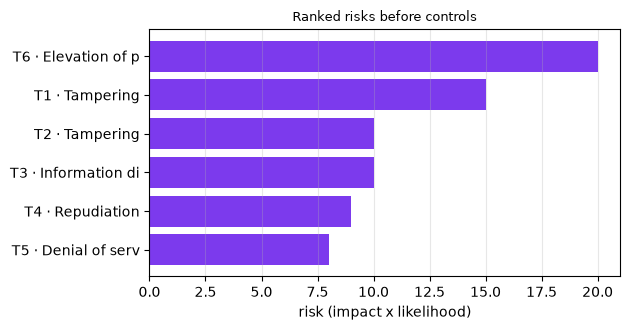

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
order = scored.sort_values("risk")
ax.barh(order.id + " · " + order.stride.str[:14], order.risk, color="#7c3aed")
ax.set_xlabel("risk (impact x likelihood)")
ax.set_title("Ranked risks before controls", fontsize=9)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — a horizontal bar chart ordered by risk. Two bars dominate; a defence budget spread
evenly across six threats would be misallocated, which is the argument for ranking at all.

### Step 5 — Check the model against its own omissions

A threat model needs a completeness test, not a feeling. Here are three cheap checks: every asset has a
threat, every threat has a control proposal, and every boundary crossing is covered by at least one
threat.

In [7]:
proposed_controls = {
    "T1": "delimit untrusted text; no tool calls from document content; cite spans",
    "T2": "signature and digest verification at load; fail closed",
    "T3": "redact identifiers before prompt assembly; output filter for ID patterns",
    "T4": "append-only audit store with hash chaining",
    "T5": "token quota and circuit breaker per identity",
    "T6": "mandatory clinician review with the source span displayed",
}
scored["control"] = scored.id.map(proposed_controls)

uncovered_assets = set(assets.id) - set(scored.asset)
uncovered_boundaries = [
    f"{r.source}->{r.destination}"
    for r in flows.itertuples()
    if r.boundary and not any(
        r.destination.split()[0] in t for t in scored.threat
    )
]
print("assets with no threat:", uncovered_assets or "none")
print("threats with no control:", set(scored.id[scored.control.isna()]) or "none")
print("boundary flows not obviously covered:", uncovered_boundaries or "none")
assert scored.control.notna().all()

assets with no threat: none
threats with no control: none
boundary flows not obviously covered: ['referral portal->summariser', 'clinician->ehr']


**Expected output** — `assets with no threat: none`, `threats with no control: none`, and a short list of
boundary flows whose coverage the string match could not confirm. That third line is the useful one: the
automated check cannot reason, so it hands you a short list to reason about yourself.

## Exercises

1. **Add the threat you think is missing.** Candidates: model drift degrading triage over time, a
   clinician sharing a summary over email, an insider editing the policy corpus. Score it.
2. **Change one assumption.** Assume the referral portal authenticates submitters. Which threat's
   likelihood changes, and by how much would you argue?
3. **Break the completeness check.** Add an asset with no threat and confirm the check catches the gap.
4. **Convert to ATLAS.** For T1 and T3, look up the ATLAS technique and note whether the identifier used
   here is the best match. Record the version of ATLAS you consulted.

## Reflection questions

1. Ranking put a human-factors threat first. Does that mean technical controls are wasted? Argue precisely.
2. The attack tree's `detectability` weighting is a judgement. What evidence would make it less of one?
3. Which single control in `proposed_controls` would you remove first under budget pressure, and what
   residual risk would you then own?

## References

1. Shostack, A., *Threat Modeling: Designing for Security*, Wiley, 2014.
2. MITRE, *ATLAS: Adversarial Threat Landscape for AI Systems*, atlas.mitre.org.
3. NIST, *AI RMF 1.0*, NIST AI 100-1, 2023 — Map and Measure functions.
4. OWASP, *Top 10 for LLM Applications*, 2025 — LLM01, LLM05, LLM06.